# Week2_ex3 — Angle-dependent impedance of a phase-shifting transformer

Reproduces Problem 3.62 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.), using the case files Problem3_62a (fixed impedance) and Problem3_62b (impedance correction table: x2.0 at -30 deg, x1.0 at 0 deg, x2.0 at +30 deg). The case file numbering follows the English edition.

![PowerWorld one-line](Images/Week2_ex3_result_image.png)

In [1]:
# 1. Case data and impedance correction table
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp

S_BASE = 500.0
V_KV = 345.0
Z_BASE = V_KV**2 / S_BASE
R_LINE, X_LINE = 0.03, 0.20
R_PST, X_PST = 0.01, 0.25
MVA_TOL = 0.5

# PowerWorld impedance correction table 1 ("New Table"): phase angle [deg] -> impedance multiplier
CORR_ANGLE = [-30.0, 0.0, 30.0]
CORR_FACTOR = [2.0, 1.0, 2.0]

steps = np.arange(-30, 31)
factor = np.interp(steps, CORR_ANGLE, CORR_FACTOR)
# The multiplier is applied to R and X together, as PowerWorld does
char_table = pd.DataFrame({
    "id_characteristic": 0, "step": steps, "voltage_ratio": 1.0, "angle_deg": steps.astype(float),
    "vk_percent": 100 * np.hypot(R_PST * factor, X_PST * factor), "vkr_percent": 100 * R_PST * factor,
})

char_table[char_table.step.isin([-30, -10, 0, 10, 30])].round(4)

,id_characteristic,step,voltage_ratio,angle_deg,vk_percent,vkr_percent
0,0,-30,1.0,-30.0,50.04,2.0000
20,0,-10,1.0,-10.0,33.36,1.3333
30,0,0,1.0,0.0,25.02,1.0000
40,0,10,1.0,10.0,33.36,1.3333
60,0,30,1.0,30.0,50.04,2.0000


In [2]:
# 2. Network builder and result extraction
def build_case(angle_deg, corrected):
    net = pp.create_empty_network(f_hz=60, sn_mva=S_BASE)
    gen_bus = pp.create_bus(net, vn_kv=V_KV, name="Generator Bus")
    load_bus = pp.create_bus(net, vn_kv=V_KV, name="Load Bus")
    pp.create_ext_grid(net, gen_bus, vm_pu=1.0, name="Slack")
    pp.create_load(net, load_bus, p_mw=500.0, q_mvar=100.0, name="Load")
    pp.create_line_from_parameters(net, gen_bus, load_bus, length_km=1.0, r_ohm_per_km=R_LINE * Z_BASE,
                                   x_ohm_per_km=X_LINE * Z_BASE, c_nf_per_km=0.0, max_i_ka=10.0, name="L2")
    params = dict(sn_mva=S_BASE, vn_hv_kv=V_KV, vn_lv_kv=V_KV,
                  vk_percent=100 * np.hypot(R_PST, X_PST), vkr_percent=100 * R_PST, pfe_kw=0.0, i0_percent=0.0,
                  tap_side="hv", tap_neutral=0, tap_min=-30, tap_max=30, tap_step_percent=0.0,
                  tap_step_degree=1.0, tap_pos=int(angle_deg), name="PST")
    if corrected:
        net.trafo_characteristic_table = char_table.copy()
        pp.create_transformer_from_parameters(net, hv_bus=load_bus, lv_bus=gen_bus, tap_changer_type="Tabular",
                                              tap_dependency_table=True, id_characteristic_table=0, **params)
    else:
        pp.create_transformer_from_parameters(net, hv_bus=load_bus, lv_bus=gen_bus, tap_changer_type="Ideal", **params)
    pp.runpp(net, numba=False)
    return net


def flows(net, corrected):
    line, pst, slack = net.res_line.iloc[0], net.res_trafo.iloc[0], net.res_ext_grid.iloc[0]
    x_now = X_PST * (np.interp(net.trafo.tap_pos.iat[0], CORR_ANGLE, CORR_FACTOR) if corrected else 1.0)
    return {
        "PST series X [pu]": x_now,
        "Load Bus voltage [kV]": net.res_bus.vm_pu.iat[1] * V_KV,
        "Slack P [MW]": slack.p_mw, "Slack Q [Mvar]": slack.q_mvar,
        "Line sending P [MW]": line.p_from_mw, "Line sending Q [Mvar]": line.q_from_mvar,
        "Line receiving P [MW]": -line.p_to_mw, "Line receiving Q [Mvar]": -line.q_to_mvar,
        "PST sending P [MW]": pst.p_lv_mw, "PST sending Q [Mvar]": pst.q_lv_mvar,
        "PST receiving P [MW]": -pst.p_hv_mw, "PST receiving Q [Mvar]": -pst.q_hv_mvar,
        "Total P loss [MW]": net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum(),
        "Total Q loss [Mvar]": net.res_line.ql_mvar.sum() + net.res_trafo.ql_mvar.sum(),
    }

In [3]:
# 3. Compare against PowerWorld at 0 and +10 deg
def compare(rows):
    """Build a PowerWorld vs pandapower table and fail loudly on any miss."""
    df = pd.DataFrame(rows, columns=["Case", "Quantity", "PowerWorld", "pandapower", "Tolerance", "Source"])
    df["Abs error"] = (df["pandapower"] - df["PowerWorld"]).abs()
    bad = df[df["Abs error"] > df["Tolerance"]]
    assert bad.empty, bad
    return df.round({"pandapower": 5, "Abs error": 5})


# PowerWorld values read once from PowerWorld Simulator (Run Mode, one-line); 3.62a and 3.62b are identical at 0 deg
T = MVA_TOL
pw = {
    ("3.62a", 0): [0.250, 330.70, 506.28, 163.06, 284.4, 76.6, 279.2, 41.8, 221.8, 86.5, 220.7, 58.2, 6.340, 63.055],
    ("3.62b", 0): [0.250, 330.70, 506.28, 163.06, 284.4, 76.6, 279.2, 41.8, 221.8, 86.5, 220.7, 58.2, 6.340, 63.055],
    ("3.62a", 10): [0.250, 331.04, 505.0, 195.0, 99.3, 87.8, 98.3, 80.8, 405.2, 107.1, 401.7, 19.2, 4.568, 94.856],
    ("3.62b", 10): [0.333, 328.43, 506.0, 199.0, 165.4, 100.0, 163.2, 85.1, 340.3, 98.6, 336.9, 14.9, 5.588, 98.616],
}
tols = [5e-4, 5e-3] + [T] * 12
rows = []
for (case, angle), values in pw.items():
    corrected = case == "3.62b"
    pp_vals = flows(build_case(angle, corrected), corrected)
    for (qty, pp_val), val, tol in zip(pp_vals.items(), values, tols):
        rows.append([f"{case}, {angle:+d} deg", qty, val, pp_val, tol, "One-line / Generators"])

compare(rows)

,Case,Quantity,PowerWorld,pandapower,Tolerance,Source,Abs error
0,"3.62a, +0 deg",PST series X [pu],0.250,0.25000,0.0005,One-line / Generators,0.00000
1,"3.62a, +0 deg",Load Bus voltage [kV],330.700,330.69904,0.0050,One-line / Generators,0.00096
2,"3.62a, +0 deg",Slack P [MW],506.280,506.34160,0.5000,One-line / Generators,0.06160
3,"3.62a, +0 deg",Slack Q [Mvar],163.060,163.06939,0.5000,One-line / Generators,0.00939
4,"3.62a, +0 deg",Line sending P [MW],284.400,284.48235,0.5000,One-line / Generators,0.08235
5,"3.62a, +0 deg",Line sending Q [Mvar],76.600,76.55882,0.5000,One-line / Generators,0.04118
6,"3.62a, +0 deg",Line receiving P [MW],279.200,279.27487,0.5000,One-line / Generators,0.07487
7,"3.62a, +0 deg",Line receiving Q [Mvar],41.800,41.84223,0.5000,One-line / Generators,0.04223
8,"3.62a, +0 deg",PST sending P [MW],221.800,221.85925,0.5000,One-line / Generators,0.05925
9,"3.62a, +0 deg",PST sending Q [Mvar],86.500,86.51057,0.5000,One-line / Generators,0.01057


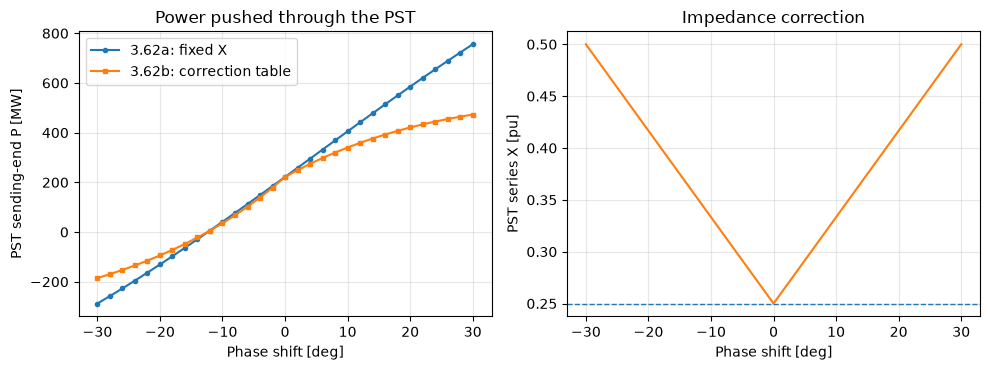

,Angle [deg],Fixed X PST P [MW],Corrected X PST P [MW],Corrected X [pu]
0,-30,-287.75,-185.06,0.50
1,-20,-130.55,-94.11,0.42
2,-10,41.26,35.50,0.33
3,0,221.86,221.86,0.25
4,10,405.21,340.25,0.33
5,20,585.18,420.88,0.42
6,30,755.66,472.69,0.50


In [4]:
# 4. Sweep the phase angle with and without correction
sweep_angles = np.arange(-30, 31, 2)
sweep = pd.DataFrame([
    {"Angle [deg]": a, **{f"{label} PST P [MW]": flows(build_case(a, c), c)["PST sending P [MW]"]
                         for label, c in [("Fixed X", False), ("Corrected X", True)]},
     "Corrected X [pu]": X_PST * np.interp(a, CORR_ANGLE, CORR_FACTOR)}
    for a in sweep_angles
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(sweep["Angle [deg]"], sweep["Fixed X PST P [MW]"], marker="o", ms=3, label="3.62a: fixed X")
ax1.plot(sweep["Angle [deg]"], sweep["Corrected X PST P [MW]"], marker="s", ms=3, label="3.62b: correction table")
ax1.set(xlabel="Phase shift [deg]", ylabel="PST sending-end P [MW]", title="Power pushed through the PST")
ax1.legend()
ax2.plot(sweep["Angle [deg]"], sweep["Corrected X [pu]"], color="tab:orange")
ax2.axhline(X_PST, ls="--", lw=1, color="tab:blue")
ax2.set(xlabel="Phase shift [deg]", ylabel="PST series X [pu]", title="Impedance correction")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("Images/Week2_ex3_pst_flow_vs_angle.png", dpi=150, bbox_inches="tight")
plt.show()

sweep[sweep["Angle [deg]"].isin([-30, -20, -10, 0, 10, 20, 30])].round(2).reset_index(drop=True)